# Implementasi SCNN untuk Klasifikasi Citra Malware

Notebook Kaggle untuk melatih Simple Convolutional Neural Network (SCNN) pada Malimg Dataset.

## Metodologi
Preprocessing ? Augmentasi ? Training SCNN ? Evaluasi ? Confusion Matrix

In [1]:
# Informasi perangkat keras untuk dokumentasi laporan
import tensorflow as tf

gpus = tf.config.list_physical_devices("GPU")
import platform
import shutil
import subprocess

print("Sistem operasi:", platform.platform())
print("Prosesor:", platform.processor())
try:
    import psutil
    print("RAM total (GB):", round(psutil.virtual_memory().total / (1024**3), 2))
except ImportError:
    print("RAM: psutil tidak tersedia")

if gpus:
    for gpu in gpus:
        print("GPU:", gpu.name)
    try:
        gpu_info = subprocess.check_output(["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv,noheader"], text=True)
        print("GPU dan VRAM:", gpu_info.strip())
    except Exception:
        print("Detail VRAM tidak dapat dibaca")
else:
    print("GPU: tidak tersedia; training menggunakan CPU")


Sistem operasi: Linux-6.18.48+-x86_64-with-glibc2.39
Prosesor: x86_64
RAM total (GB): 31.35
GPU: /physical_device:GPU:0
GPU: /physical_device:GPU:1
GPU dan VRAM: Tesla T4, 15360 MiB
Tesla T4, 15360 MiB


Dataset: /kaggle/input/datasets/manmandes/malimg
Jumlah gambar: 9339
Jumlah folder: 1
Found 9339 files belonging to 1 classes.
Using 7472 files for training.


I0000 00:00:1792666569.814833      22 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792666569.819222      22 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Found 9339 files belonging to 1 classes.
Using 1867 files for validation.
Jumlah kelas: 1
Kelas: ['malimg_dataset']


Model: "malware_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 128, 128, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 128, 128, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 65536)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     8,388,736 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

...

 Trainable params: 8,407,681 (32.07 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30


/usr/local/lib/python3.13/dist-packages/keras/src/ops/nn.py:947: UserWarning: You are using a softmax over axis -1 of a tensor of shape (None, 1). This axis has size 1. The softmax operation will always return the value 1, which is likely not what you intended. Did you mean to use a sigmoid instead?
  warnings.warn(


234/234 ━━━━━━━━━━━━━━━━━━━━ 285s 1s/step - accuracy: 0.0000e+00 - loss: 0.0000e+00 - val_accuracy: 0.0000e+00 - val_loss: 0.0000e+00 - learning_rate: 0.0010
Epoch 2/30
234/234 ━━━━━━━━━━━━━━━━━━━━ 8s 35ms/step - accuracy: 0.0000e+00 - loss: 0.0000e+00 - val_accuracy: 0.0000e+00 - val_loss: 0.0000e+00 - learning_rate: 0.0010
Epoch 3/30
234/234 ━━━━━━━━━━━━━━━━━━━━ 8s 36ms/step - accuracy: 0.0000e+00 - loss: 0.0000e+00 - val_accuracy: 0.0000e+00 - val_loss: 0.0000e+00 - learning_rate: 0.0010
Epoch 4/30
234/234 ━━━━━━━━━━━━━━━━━━━━ 8s 35ms/step - accuracy: 0.0000e+00 - loss: 0.0000e+00 - val_accuracy: 0.0000e+00 - val_loss: 0.0000e+00 - learning_rate: 0.0010
Epoch 5/30
234/234 ━━━━━━━━━━━━━━━━━━━━ 8s 35ms/step - accuracy: 0.0000e+00 - loss: 0.0000e+00 - val_accuracy: 0.0000e+00 - val_loss: 0.0000e+00 - learning_rate: 3.0000e-04
Epoch 6/30
234/234 ━━━━━━━━━━━━━━━━━━━━ 8s 35ms/step - accuracy: 0.0000e+00 - loss: 0.0000e+00 - val_accuracy: 0.0000e+00 - val_loss: 0.0000e+00 - learning_rate: 

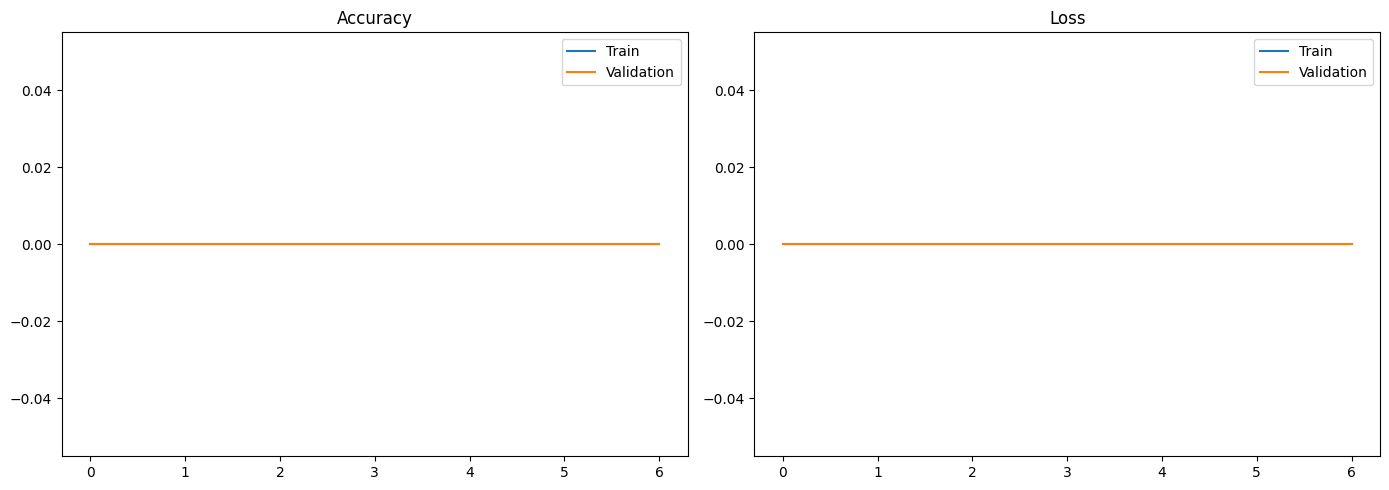

/usr/local/lib/python3.13/dist-packages/keras/src/ops/nn.py:947: UserWarning: You are using a softmax over axis -1 of a tensor of shape (32, 1). This axis has size 1. The softmax operation will always return the value 1, which is likely not what you intended. Did you mean to use a sigmoid instead?
  warnings.warn(


                precision    recall  f1-score   support

malimg_dataset       1.00      1.00      1.00      1867

      accuracy                           1.00      1867
     macro avg       1.00      1.00      1.00      1867
  weighted avg       1.00      1.00      1.00      1867



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:407: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


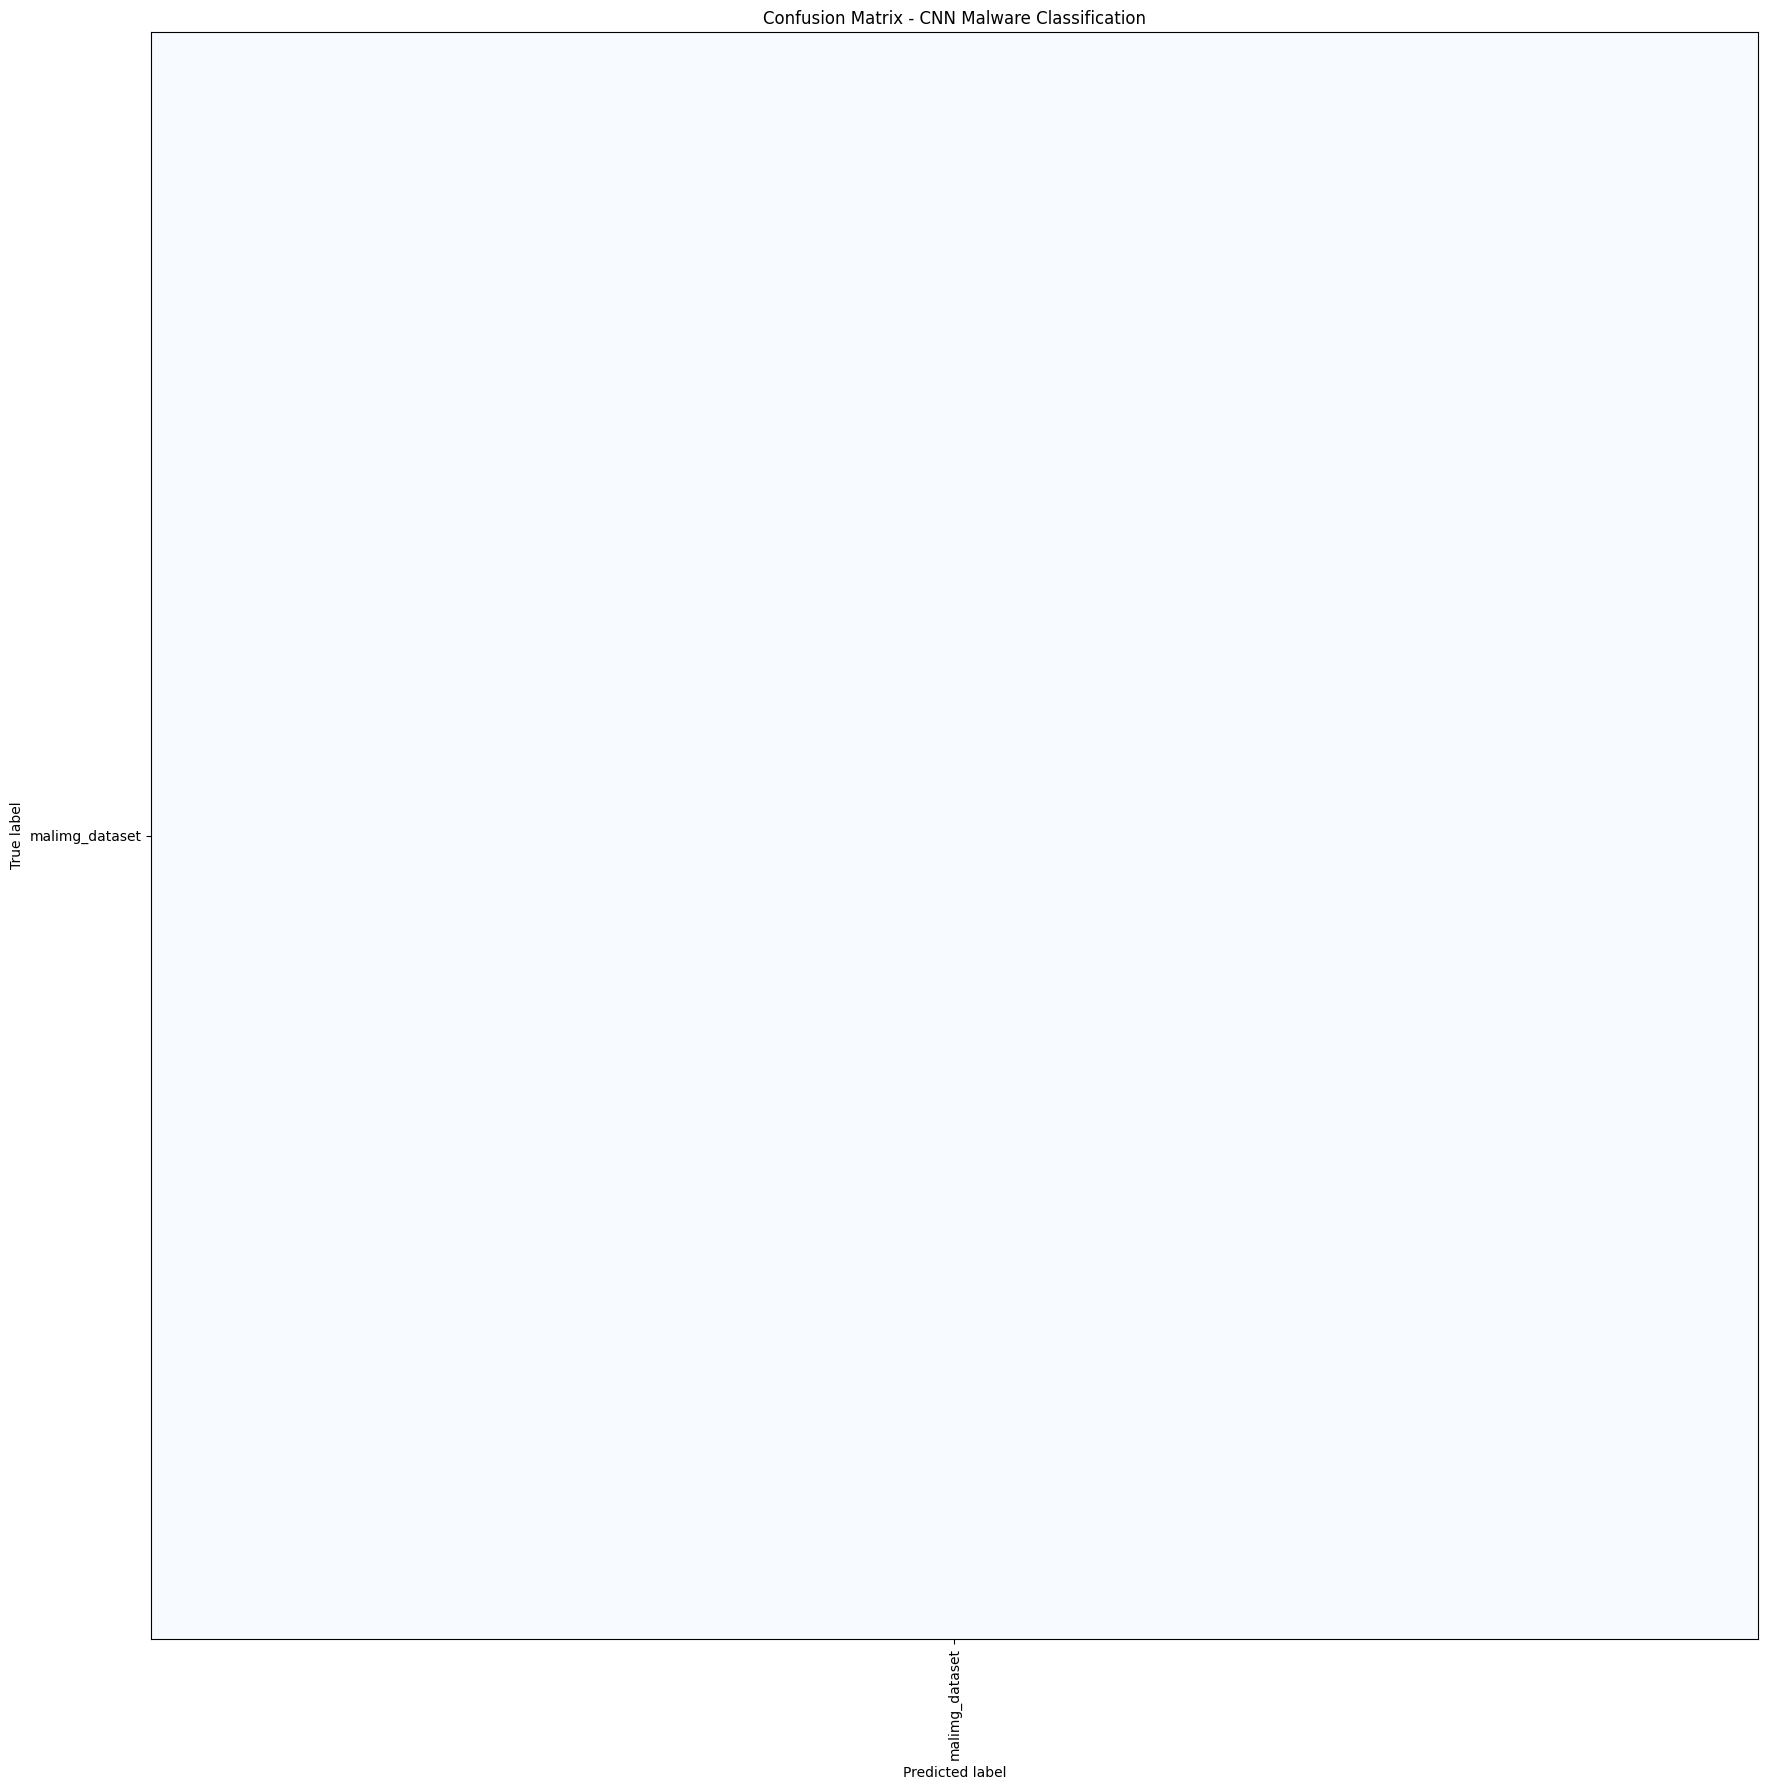

Model tersimpan sebagai malware_cnn.keras


In [2]:
"""CNN Malware Image Classification.

Script ini dapat dijalankan di Kaggle Notebook atau diubah menjadi cell notebook.
Dataset Malimg harus ditambahkan melalui Add Input.
"""

import os
import random
from pathlib import Path

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay


SEED = 42
IMAGE_SIZE = (128, 128)
BATCH_SIZE = 32
EPOCHS = 30

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)


def find_dataset_root(base_dir="/kaggle/input"):
    """Find the folder containing class subfolders with image files."""
    image_extensions = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff", ".webp"}
    base_path = Path(base_dir)
    image_files = [
        p for p in base_path.rglob("*")
        if p.is_file() and p.suffix.lower() in image_extensions
    ]
    if not image_files:
        raise FileNotFoundError(
            "Tidak ada file gambar ditemukan di /kaggle/input. "
            "Pastikan dataset sudah ditambahkan melalui Add Input."
        )

    class_folders = sorted(set(p.parent for p in image_files))
    candidates = {}
    for class_folder in class_folders:
        dataset_folder = class_folder.parent
        candidates.setdefault(dataset_folder, set()).add(class_folder)

    dataset_root = max(candidates, key=lambda folder: len(candidates[folder]))
    selected_images = [p for p in image_files if p.parent.parent == dataset_root]
    print("Dataset ditemukan:", dataset_root)
    print("Jumlah kelas:", len(candidates[dataset_root]))
    print("Jumlah gambar:", len(selected_images))
    return dataset_root
def build_datasets(dataset_root):
    train_ds = tf.keras.utils.image_dataset_from_directory(
        dataset_root,
        validation_split=0.2,
        subset="training",
        seed=SEED,
        image_size=IMAGE_SIZE,
        batch_size=BATCH_SIZE,
        color_mode="grayscale",
    )
    val_ds = tf.keras.utils.image_dataset_from_directory(
        dataset_root,
        validation_split=0.2,
        subset="validation",
        seed=SEED,
        image_size=IMAGE_SIZE,
        batch_size=BATCH_SIZE,
        color_mode="grayscale",
    )
    return train_ds, val_ds


def build_model(num_classes):
    augmentation = tf.keras.Sequential([
        tf.keras.layers.RandomRotation(0.05),
        tf.keras.layers.RandomZoom(0.10),
        tf.keras.layers.RandomTranslation(0.05, 0.05),
    ], name="augmentation")
    inputs = tf.keras.Input(shape=(*IMAGE_SIZE, 1))
    x = augmentation(inputs)
    x = tf.keras.layers.Rescaling(1.0 / 255)(x)
    for filters in (32, 64):
        x = tf.keras.layers.Conv2D(filters, 3, padding="same", activation="relu")(x)
        x = tf.keras.layers.MaxPooling2D()(x)
    x = tf.keras.layers.Flatten()(x)
    x = tf.keras.layers.Dense(128, activation="relu")(x)
    x = tf.keras.layers.Dropout(0.40)(x)
    outputs = tf.keras.layers.Dense(num_classes, activation="softmax")(x)
    model = tf.keras.Model(inputs, outputs, name="malware_cnn")
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model


def plot_history(history):
    figure, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].plot(history.history["accuracy"], label="Train")
    axes[0].plot(history.history["val_accuracy"], label="Validation")
    axes[0].set_title("Accuracy")
    axes[0].legend()
    axes[1].plot(history.history["loss"], label="Train")
    axes[1].plot(history.history["val_loss"], label="Validation")
    axes[1].set_title("Loss")
    axes[1].legend()
    plt.tight_layout()
    plt.show()


# Lokasi dataset Malimg pada Kaggle
from pathlib import Path

image_extensions = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff", ".webp"}
base_dataset = Path("/kaggle/input/datasets/manmandes/malimg")

if not base_dataset.exists():
    raise FileNotFoundError(f"Dataset tidak ditemukan: {base_dataset}")

def count_class_folders(folder):
    return sum(
        1 for child in folder.iterdir()
        if child.is_dir() and any(
            p.is_file() and p.suffix.lower() in image_extensions
            for p in child.rglob("*")
        )
    )

# Mencari folder yang langsung berisi subfolder kelas.
candidates = [p for p in base_dataset.rglob("*") if p.is_dir()]
candidates.append(base_dataset)
valid_candidates = [(p, count_class_folders(p)) for p in candidates]
valid_candidates = [(p, n) for p, n in valid_candidates if n >= 2]

if not valid_candidates:
    raise FileNotFoundError(
        "Folder kelas malware tidak ditemukan. Periksa struktur dataset pada Add Input."
    )

dataset_root, class_count = max(valid_candidates, key=lambda item: item[1])
image_files = [
    p for p in dataset_root.rglob("*")
    if p.is_file() and p.suffix.lower() in image_extensions
]

print("Dataset root:", dataset_root)
print("Jumlah kelas:", class_count)

if class_count < 2:
    raise ValueError(
        f"Dataset hanya terbaca sebagai {class_count} kelas. Gunakan folder yang langsung berisi subfolder keluarga malware."
    )

print("Jumlah gambar:", len(image_files))

train_ds, val_ds = build_datasets(dataset_root)
class_names = train_ds.class_names
print("Jumlah kelas:", len(class_names))
print("Kelas:", class_names)

autotune = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(autotune)
val_ds = val_ds.prefetch(autotune)
model = build_model(len(class_names))
model.summary()

callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=3),
]
history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, callbacks=callbacks)
plot_history(history)

y_true, y_pred = [], []
for images, labels in val_ds:
    predictions = model.predict(images, verbose=0)
    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

print(classification_report(y_true, y_pred, target_names=class_names, zero_division=0))
cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(cm, display_labels=class_names)
fig, ax = plt.subplots(figsize=(18, 18))
disp.plot(ax=ax, xticks_rotation=90, cmap="Blues", colorbar=False)
plt.title("Confusion Matrix - CNN Malware Classification")
plt.tight_layout()
plt.show()

model.save("malware_cnn.keras")
print("Model tersimpan sebagai malware_cnn.keras")


In [3]:
# Tabel ringkasan hasil untuk BAB IV
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

results_table = pd.DataFrame([{
    "Accuracy": accuracy_score(y_true, y_pred),
    "Precision Macro": precision_score(y_true, y_pred, average="macro", zero_division=0),
    "Recall Macro": recall_score(y_true, y_pred, average="macro", zero_division=0),
    "F1-Score Macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
}]).round(4)
results_table


,Accuracy,Precision Macro,Recall Macro,F1-Score Macro
0,1.0,1.0,1.0,1.0
